# **PROJETO STP - M5 Forescasting**

### **Projeto desenvolvido por:**
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---

# **Phase 1 - Statistical Models - AutoARIMA**

## **1. Imports and Data Upload**

In [ ]:
!pip install statsforecast

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.6/354.6 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.2/348.2 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 3.2 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3


In [ ]:
from google.colab import files
import io

import pandas as pd
import numpy as np

from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA
from statsforecast.arima import arima_string

import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats
from sklearn import metrics

In [ ]:
#Carregar o ficheiro com os dados do departamento escolhido e dos resultados dos BaselineModels

uploaded = files.upload()

if 'HOBBIES_2_TX1.csv' in uploaded and 'Results_BaselineModels.csv' in uploaded:
    Y_df_HOBBIES_2_TX1 = pd.read_csv(io.BytesIO(uploaded['HOBBIES_2_TX1.csv']), parse_dates=['ds'])
    Baseline_results = pd.read_csv(io.BytesIO(uploaded['Results_BaselineModels.csv']), sep=',')
    print("Both files uploaded successfully.")
else:
    print("Please ensure both 'HOBBIES_2_TX1.csv' and 'Results_BaselineModels.csv' are uploaded.")

Y_df_HOBBIES_2_TX1

Saving HOBBIES_2_TX1.csv to HOBBIES_2_TX1.csv
Saving Results_BaselineModels.csv to Results_BaselineModels.csv
Both files uploaded successfully.


,unique_id,ds,y
0,HOBBIES_2_001_TX_1,2011-02-11,1.0
1,HOBBIES_2_001_TX_1,2011-02-12,0.0
2,HOBBIES_2_001_TX_1,2011-02-13,0.0
3,HOBBIES_2_001_TX_1,2011-02-14,0.0
4,HOBBIES_2_001_TX_1,2011-02-15,0.0
...,...,...,...
221726,HOBBIES_2_149_TX_1,2016-06-15,0.0
221727,HOBBIES_2_149_TX_1,2016-06-16,0.0
221728,HOBBIES_2_149_TX_1,2016-06-17,0.0
221729,HOBBIES_2_149_TX_1,2016-06-18,2.0


In [ ]:
train = Y_df_HOBBIES_2_TX1[Y_df_HOBBIES_2_TX1['ds'] <= '2016-05-22'] #Selecionar os dados anteriores aos últimos 28 dias de cada série
train

,unique_id,ds,y
0,HOBBIES_2_001_TX_1,2011-02-11,1.0
1,HOBBIES_2_001_TX_1,2011-02-12,0.0
2,HOBBIES_2_001_TX_1,2011-02-13,0.0
3,HOBBIES_2_001_TX_1,2011-02-14,0.0
4,HOBBIES_2_001_TX_1,2011-02-15,0.0
...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0


In [ ]:
test = Y_df_HOBBIES_2_TX1[Y_df_HOBBIES_2_TX1['ds'] > '2016-05-22'] #Selecionar os últimos 28 dias de cada série
test

,unique_id,ds,y
1928,HOBBIES_2_001_TX_1,2016-05-23,0.0
1929,HOBBIES_2_001_TX_1,2016-05-24,0.0
1930,HOBBIES_2_001_TX_1,2016-05-25,0.0
1931,HOBBIES_2_001_TX_1,2016-05-26,0.0
1932,HOBBIES_2_001_TX_1,2016-05-27,0.0
...,...,...,...
221726,HOBBIES_2_149_TX_1,2016-06-15,0.0
221727,HOBBIES_2_149_TX_1,2016-06-16,0.0
221728,HOBBIES_2_149_TX_1,2016-06-17,0.0
221729,HOBBIES_2_149_TX_1,2016-06-18,2.0


In [ ]:
train.shape, test.shape

((217559, 3), (4172, 3))

## **2. AutoARIMA**

O modelo AutoARIMA será, à semelhança do documento anterior dos *Baseline Models*, programado para estimar os valores futuros das séries temporais num horizonte de 28 dias, adotando a frequência diária (`freq = 'D'`) e sazonalidade semanal (`season_length = 7`).
A implementação é feita com recurso à biblioteca StatsForecast, incluindo a geração de intervalos de previsão com nível de confiança de 95%.


In [ ]:
freq = 'D'
season_length = 7
horizon = 28

In [ ]:
sf = StatsForecast(
    models=[AutoARIMA(season_length=season_length)],
    freq=freq,
    n_jobs=-1
    )

In [ ]:
sf.fit(train)

StatsForecast(models=[AutoARIMA])

In [ ]:
arima_string(sf.fitted_[0,0].model_)

'ARIMA(0,1,1) with drift        '

In [ ]:
result = sf.fitted_[0,0].model_
print(result.keys())
print(result['arma'])    # (p,q,P,Q,m,d,D)

dict_keys(['coef', 'sigma2', 'var_coef', 'mask', 'loglik', 'aic', 'arma', 'residuals', 'code', 'n_cond', 'nobs', 'model', 'xreg', 'bic', 'aicc', 'ic', 'x', 'lambda'])
(0, 1, 0, 0, 1, 1, 0)


O vetor `(0, 1, 0, 0, 1, 1, 0)` corresponde à forma como o software representa internamente a estrutura do modelo ARIMA. Os três primeiros valores indicam a parte não sazonal: não existe componente autoregressiva (p = 0), a série foi diferenciada uma vez (d = 1) e não há termo de média móvel não sazonal (q = 0). Os valores seguintes referem‑se à componente sazonal, mostrando ausência de termo AR sazonal (P = 0), uma diferenciação sazonal (D = 1) e um termo MA sazonal (Q = 1). O último valor (m = 0) indica que não foi definida qualquer periodicidade sazonal, pelo que a componente sazonal não é efetivamente utilizada.


In [ ]:
residual = pd.DataFrame(result.get("residuals"), columns=["residuals ARIMA"])
residual

,residuals ARIMA
0,0.001000
1,-0.707123
2,-0.408278
3,-0.288717
4,-0.223661
...,...
1923,-0.065414
1924,-0.065405
1925,-0.065395
1926,-0.065385


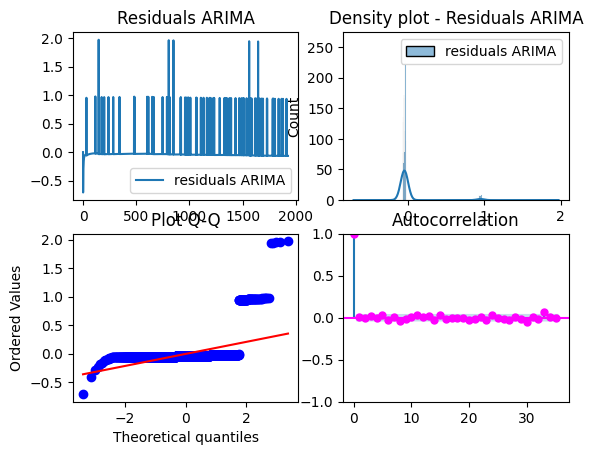

In [ ]:
fig, axs = plt.subplots(nrows=2, ncols=2)

residual.plot(ax=axs[0,0])
axs[0,0].set_title("Residuals ARIMA");

sns.histplot(residual, kde=True, ax=axs[0,1])
axs[0,1].set_title("Density plot - Residuals ARIMA");

stats.probplot(residual["residuals ARIMA"], dist="norm", plot=axs[1,0])
axs[1,0].set_title('Plot Q-Q')

plot_acf(residual, lags=35, ax=axs[1,1], color="fuchsia")
axs[1,1].set_title("Autocorrelation");

plt.show();

In [ ]:
levels = [95]

forecasts = sf.forecast(df=train, h=horizon, level=levels)

forecasts

,unique_id,ds,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-hi-95
0,HOBBIES_2_001_TX_1,2016-05-23,0.065383,-0.351987,0.482752
1,HOBBIES_2_001_TX_1,2016-05-24,0.065407,-0.351962,0.482776
2,HOBBIES_2_001_TX_1,2016-05-25,0.065431,-0.351938,0.482801
3,HOBBIES_2_001_TX_1,2016-05-26,0.065455,-0.351914,0.482825
4,HOBBIES_2_001_TX_1,2016-05-27,0.065480,-0.351890,0.482849
...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.466723,-1.073342,2.006788
4168,HOBBIES_2_149_TX_1,2016-06-16,0.466723,-1.074086,2.007532
4169,HOBBIES_2_149_TX_1,2016-06-17,0.466723,-1.074830,2.008276
4170,HOBBIES_2_149_TX_1,2016-06-18,0.466723,-1.075573,2.009019


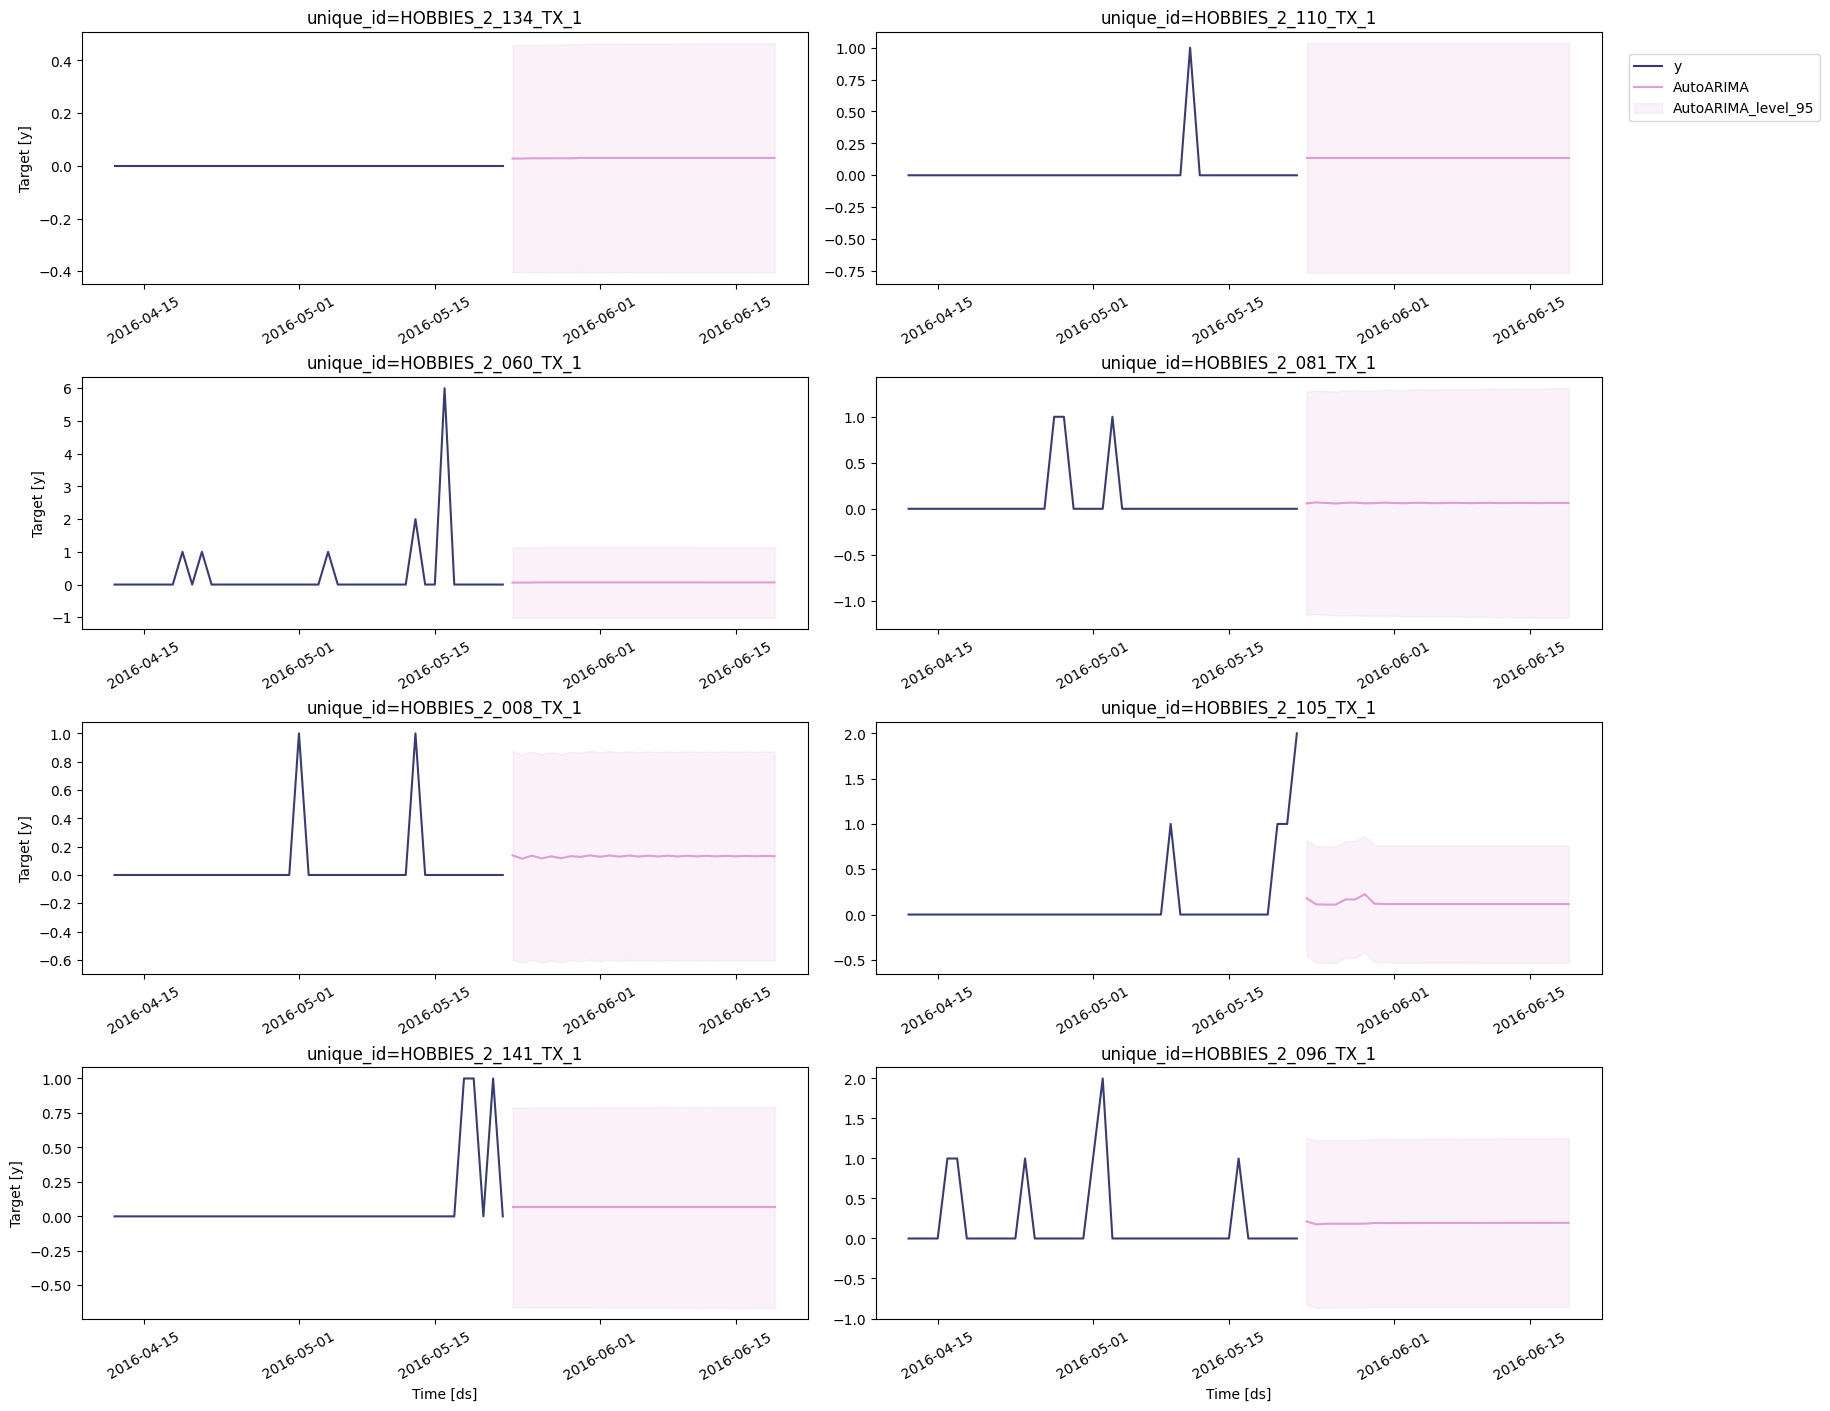

In [ ]:
cutoff = train["ds"].max() - pd.Timedelta(days=40)
train_last_40_days = train[train["ds"] >= cutoff]

sf.plot(train_last_40_days, forecasts, level=levels)

## **3. Evaluation metrics and model comparison**

In [ ]:
def rmsse(y, y_hat, y_train, seasonality):
    delta_y = np.mean((y - y_hat) ** 2)

    scale = np.mean((y_train[:-seasonality] - y_train[seasonality:]) ** 2)

    if scale < 1e-8:
        return np.nan

    return np.sqrt(delta_y / scale)


def mase(y, y_hat, y_train, seasonality):
    delta_y = np.mean(np.abs(y - y_hat))

    scale = np.mean(np.abs(y_train[:-seasonality] - y_train[seasonality:]))

    if scale < 1e-8:
        return np.nan

    return delta_y / scale


def model_evaluation(y_hist, y_true, y_pred, Model, seasonality):

    mse = metrics.mean_squared_error(y_true, y_pred)

    results_row = [{
        "Model": Model,
        "MSE": mse,
        "MAE": metrics.mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mse),
        "RMSSE": rmsse(y_true.values, y_pred.values, y_hist.values, seasonality),
        "MASE": mase(y_true.values, y_pred.values, y_hist.values, seasonality)
    }]

    return pd.DataFrame(results_row)

In [ ]:
Models_results = pd.DataFrame()

new_result = model_evaluation(
    train["y"],
    test["y"],
    forecasts["AutoARIMA"],
    "AutoARIMA",
    season_length
)

Models_results = pd.concat([Models_results, new_result], ignore_index=True)

Final_results = pd.concat([Baseline_results, Models_results], ignore_index=True)

Final_results.to_csv("Results_AutoARIMA.csv", index=False)

Final_results

,Model,MSE,MAE,RMSE,RMSSE,MASE
0,Naive,1.093480,0.509588,1.045696,1.108525,1.559721
1,SeasonalNaive,1.131352,0.493768,1.063650,1.127558,1.511300
2,HistoricAverage,0.433728,0.342736,0.658580,0.698150,1.049029
3,RandomWalkWithDrift,1.105867,0.522300,1.051602,1.114786,1.598628
4,AutoARIMA,0.458665,0.373214,0.677248,0.717940,1.142315


Através das métricas acima apresentadas podemos concluir que o modelo `HistoricAverage` continua a demonstrar um desempenho superior aos restantes modelos, dado que os valores do `AutoARIMA` são superiores em todas as métricas. Contudo, comparando o modelo do atual documento com os restantes do `Baseline Models` verificamos um desempenho significativamente superior em todas as métricas.

## **4. Regressors**

In [ ]:
base_url = 'https://datasets-nixtla.s3.amazonaws.com'

X_df = pd.read_parquet(f'{base_url}/m5_x.parquet')

In [ ]:
X_df_HOBBIES2 = X_df[X_df['unique_id'].str.startswith('HOBBIES_2')]
X_df_HOBBIES2_TX1 = X_df_HOBBIES2[X_df_HOBBIES2['unique_id'].str.endswith('TX_1')]
X_df_HOBBIES2_TX1

,unique_id,ds,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
28860162,HOBBIES_2_001_TX_1,2011-02-11,nan,nan,nan,nan,0,1,1,5.47
28860163,HOBBIES_2_001_TX_1,2011-02-12,nan,nan,nan,nan,0,1,1,5.47
28860164,HOBBIES_2_001_TX_1,2011-02-13,nan,nan,nan,nan,0,1,0,5.47
28860165,HOBBIES_2_001_TX_1,2011-02-14,ValentinesDay,Cultural,nan,nan,0,0,1,5.47
28860166,HOBBIES_2_001_TX_1,2011-02-15,nan,nan,nan,nan,0,1,1,5.47
...,...,...,...,...,...,...,...,...,...,...
31097066,HOBBIES_2_149_TX_1,2016-06-15,nan,nan,nan,nan,0,1,1,0.97
31097067,HOBBIES_2_149_TX_1,2016-06-16,nan,nan,nan,nan,0,0,0,0.97
31097068,HOBBIES_2_149_TX_1,2016-06-17,nan,nan,nan,nan,0,0,0,0.97
31097069,HOBBIES_2_149_TX_1,2016-06-18,nan,nan,nan,nan,0,0,0,0.97


In [ ]:
regressors_train = X_df_HOBBIES2_TX1[X_df_HOBBIES2_TX1['ds'] <= '2016-05-22']
regressors_test = X_df_HOBBIES2_TX1[X_df_HOBBIES2_TX1['ds'] > '2016-05-22']

In [ ]:
regressors_train = regressors_train[['unique_id', 'ds', 'sell_price', 'snap_TX']]
regressors_train

,unique_id,ds,sell_price,snap_TX
28860162,HOBBIES_2_001_TX_1,2011-02-11,5.47,1
28860163,HOBBIES_2_001_TX_1,2011-02-12,5.47,1
28860164,HOBBIES_2_001_TX_1,2011-02-13,5.47,1
28860165,HOBBIES_2_001_TX_1,2011-02-14,5.47,0
28860166,HOBBIES_2_001_TX_1,2011-02-15,5.47,1
...,...,...,...,...
31097038,HOBBIES_2_149_TX_1,2016-05-18,0.97,0
31097039,HOBBIES_2_149_TX_1,2016-05-19,0.97,0
31097040,HOBBIES_2_149_TX_1,2016-05-20,0.97,0
31097041,HOBBIES_2_149_TX_1,2016-05-21,0.97,0


In [ ]:
regressors_test = regressors_test[['unique_id', 'ds', 'sell_price', 'snap_TX']]
regressors_test

,unique_id,ds,sell_price,snap_TX
28862090,HOBBIES_2_001_TX_1,2016-05-23,5.47,0
28862091,HOBBIES_2_001_TX_1,2016-05-24,5.47,0
28862092,HOBBIES_2_001_TX_1,2016-05-25,5.47,0
28862093,HOBBIES_2_001_TX_1,2016-05-26,5.47,0
28862094,HOBBIES_2_001_TX_1,2016-05-27,5.47,0
...,...,...,...,...
31097066,HOBBIES_2_149_TX_1,2016-06-15,0.97,1
31097067,HOBBIES_2_149_TX_1,2016-06-16,0.97,0
31097068,HOBBIES_2_149_TX_1,2016-06-17,0.97,0
31097069,HOBBIES_2_149_TX_1,2016-06-18,0.97,0


In [ ]:
regressors_train.shape, regressors_test.shape

((217559, 4), (4172, 4))

In [ ]:
train = train.merge(regressors_train, how='left', on=['unique_id', 'ds'])
train

,unique_id,ds,y,sell_price,snap_TX
0,HOBBIES_2_001_TX_1,2011-02-11,1.0,5.47,1
1,HOBBIES_2_001_TX_1,2011-02-12,0.0,5.47,1
2,HOBBIES_2_001_TX_1,2011-02-13,0.0,5.47,1
3,HOBBIES_2_001_TX_1,2011-02-14,0.0,5.47,0
4,HOBBIES_2_001_TX_1,2011-02-15,0.0,5.47,1
...,...,...,...,...,...
217554,HOBBIES_2_149_TX_1,2016-05-18,3.0,0.97,0
217555,HOBBIES_2_149_TX_1,2016-05-19,0.0,0.97,0
217556,HOBBIES_2_149_TX_1,2016-05-20,0.0,0.97,0
217557,HOBBIES_2_149_TX_1,2016-05-21,1.0,0.97,0


In [ ]:
levels = [95]

In [ ]:
forecasts_regressors = sf.forecast(df=train, h=horizon, X_df=regressors_test, level=levels)
forecasts_regressors

,unique_id,ds,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-hi-95
0,HOBBIES_2_001_TX_1,2016-05-23,0.069698,-0.347745,0.487142
1,HOBBIES_2_001_TX_1,2016-05-24,0.069723,-0.347721,0.487166
2,HOBBIES_2_001_TX_1,2016-05-25,0.069747,-0.347696,0.487191
3,HOBBIES_2_001_TX_1,2016-05-26,0.069772,-0.347672,0.487215
4,HOBBIES_2_001_TX_1,2016-05-27,0.069796,-0.347647,0.487240
...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.507539,-1.016166,2.031244
4168,HOBBIES_2_149_TX_1,2016-06-16,0.434254,-1.089500,1.958009
4169,HOBBIES_2_149_TX_1,2016-06-17,0.405110,-1.118674,1.928894
4170,HOBBIES_2_149_TX_1,2016-06-18,0.449370,-1.074433,1.973173


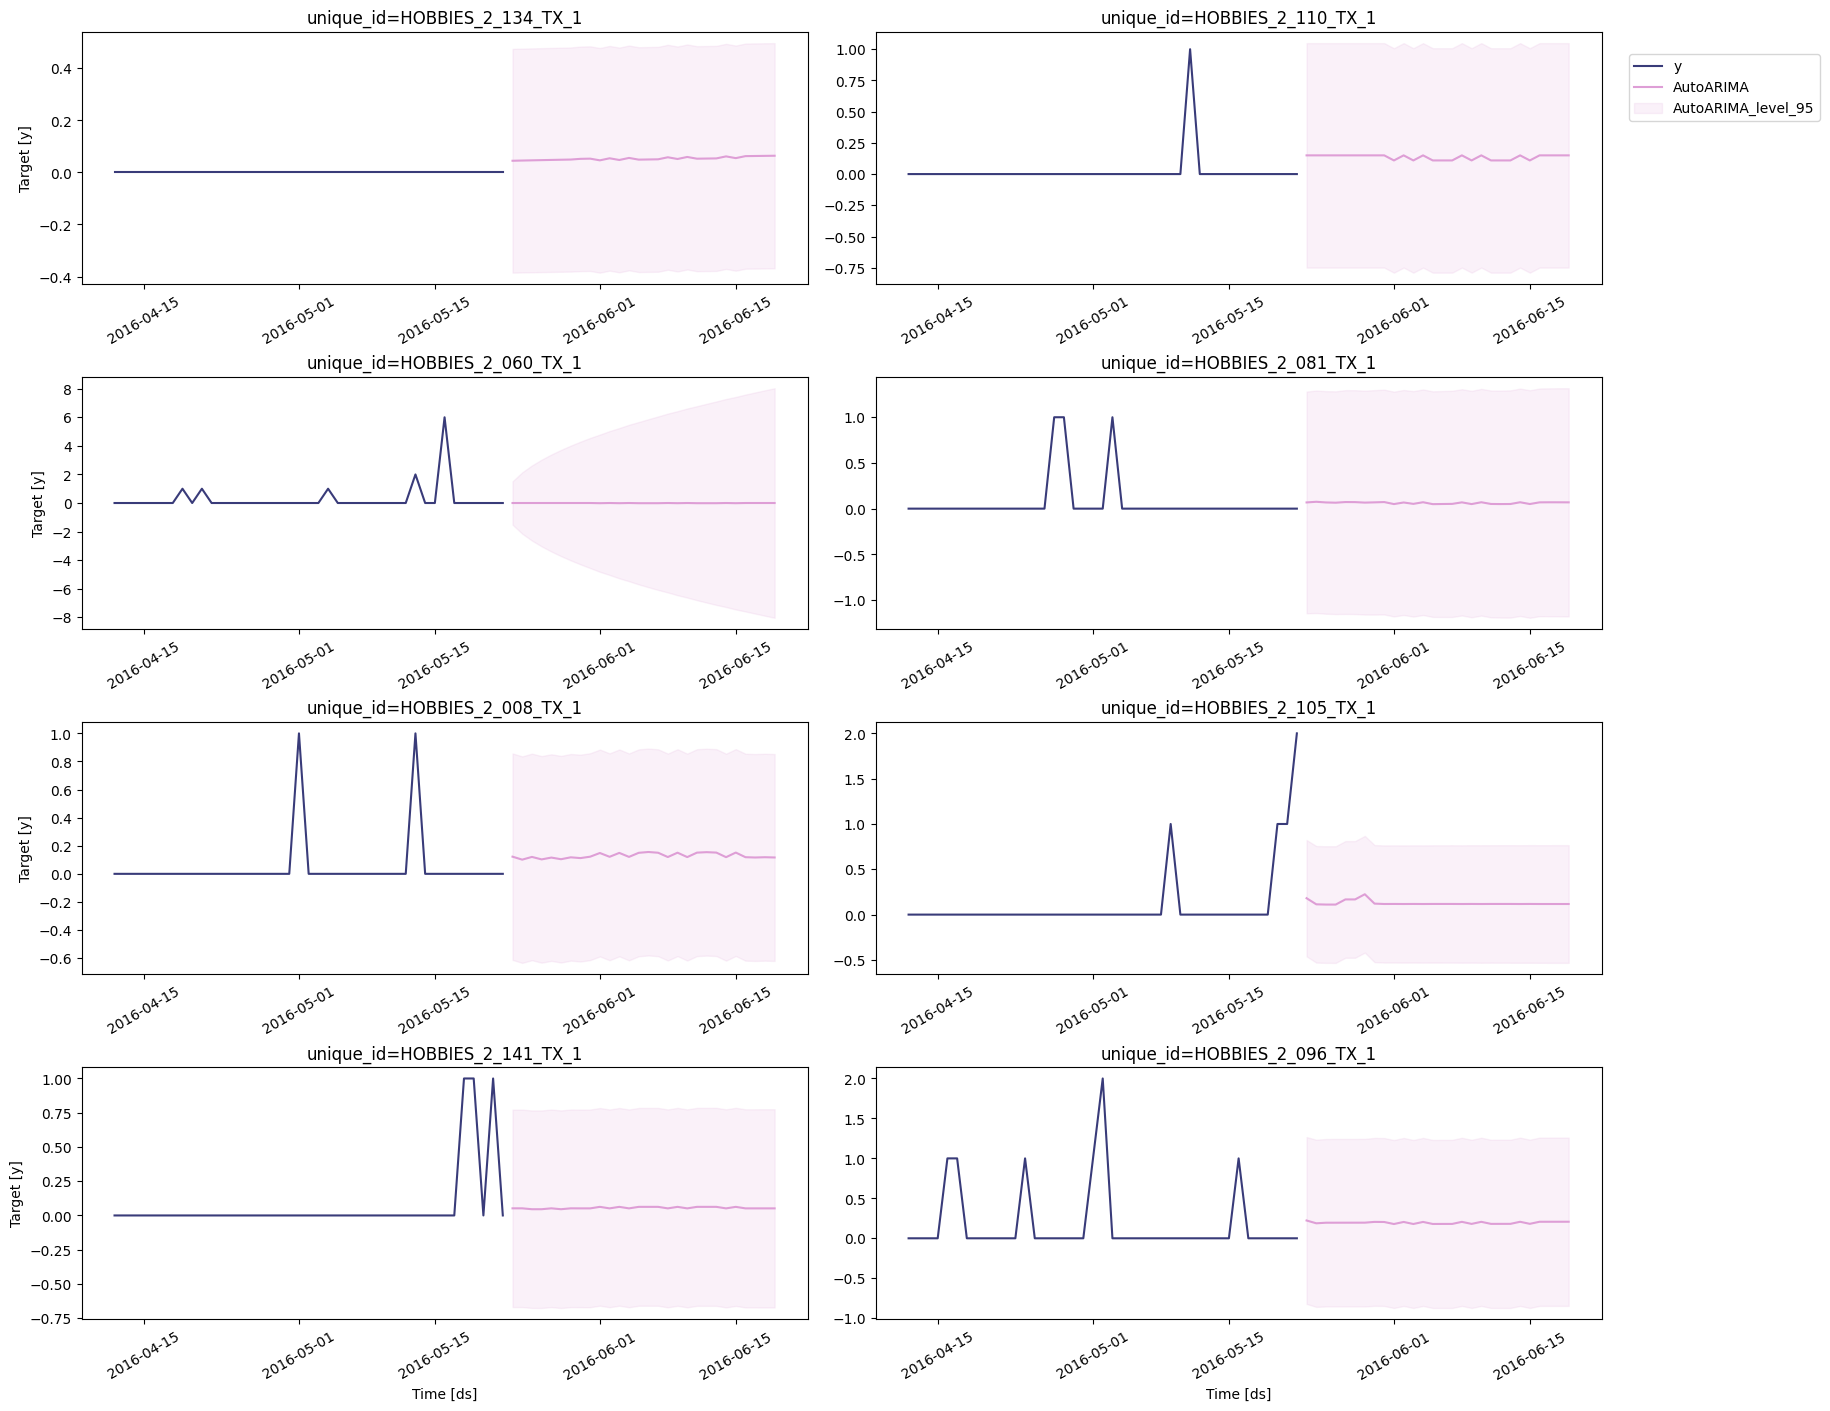

In [ ]:
cutoff = train["ds"].max() - pd.Timedelta(days=40)
train_last_40_days = train[train["ds"] >= cutoff]

sf.plot(train_last_40_days, forecasts_regressors, level=levels)

In [ ]:
Results_regressors = test.merge(forecasts_regressors, how='left', on=['unique_id', 'ds'])

Results_regressors.to_csv('Results_Regressors.csv', index=False)

Results_regressors

,unique_id,ds,y,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-hi-95
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.069698,-0.347745,0.487142
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.069723,-0.347721,0.487166
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.069747,-0.347696,0.487191
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.069772,-0.347672,0.487215
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.069796,-0.347647,0.487240
...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.0,0.507539,-1.016166,2.031244
4168,HOBBIES_2_149_TX_1,2016-06-16,0.0,0.434254,-1.089500,1.958009
4169,HOBBIES_2_149_TX_1,2016-06-17,0.0,0.405110,-1.118674,1.928894
4170,HOBBIES_2_149_TX_1,2016-06-18,2.0,0.449370,-1.074433,1.973173


Após correr o autoARIMA com regressores verificamos que os intervalores de confiança e previsões do horizonte são muito similares às do `AutoARIMA` sem regressores, pelo que, os mesmos não acrescentam informação relevante para melhorar a perfomance do modelo e o seu *forecast*.